# 2. GOTOBI EFFECT · IN-SAMPLE SENSITIVITY & PLATEAU CHECK

In-sample sensitivity of the **USDJPY Gotobi** rule (long 07:30 -> 09:55 JST on Gotobi days, M5 bars, UTC), following the flow of notebook 02 of the Monday / RSI2 edges.

### STRICT METHODOLOGICAL CONSTRAINT
> **IN-SAMPLE ONLY**: everything before `splits.oos_start`. The OOS block belongs to notebook 03.
> Gotobi days and times are **not optimised** (frozen in the YAML). This notebook measures how fragile the frozen rule is; **nothing is re-tuned here**.

### OBJECTIVES
1. **Time-window plateau**: entry x exit grid around the frozen window must be a stable region, not an isolated peak (plateau + anti-cliff).
2. **Cost sensitivity**: flat-spread and feed-scale sweeps, breakeven spread and breakeven multiple.
3. **Calendar anatomy**: which Gotobi days / weekdays / seasons carry the edge, leave-one-label-out, alternative calendar conventions.
4. **Execution filter & spread**: how the entry spread (a winter-rollover effect) interacts with edge, and what the spread filter costs in signals.
5. **Stability through time**: by year, by period, rolling window.

Every gate goes into one `Checks` registry (section 8) that is saved for notebook 03 (section 9).

In [12]:
VARIANT = "v1_axi_usdjpy"              # variants/<name>.yaml
GRID_SPAN_MIN, GRID_STEP_MIN = 30, 10   # time grid: frozen entry/exit +- span, every step (minutes)
ROLL_BINS = 5                      # quantile buckets for the entry-spread analysis

## 1. IMPORTS AND CONFIG

In [13]:
import sys, importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_edge_dir(start=None):
    """Folder that holds BOTH variants/ and gotobi_engine.py (notebooks, engine, utils and variants/ live together).
    Looks in cwd and its parents, then one or two levels below each of them."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        for cand in (base, *base.glob("*"), *base.glob("*/*")):
            if cand.is_dir() and (cand / "variants").is_dir() and (cand / "gotobi_engine.py").is_file():
                return cand
    raise FileNotFoundError(
        f"Could not find a folder with 'variants/' AND 'gotobi_engine.py' near {here}. "
        "Put gotobi_engine.py, gotobi_utils.py and variant_config.py next to variants/ (02_strategy_development/Gotobi/).")

EDGE_DIR = find_edge_dir()
if str(EDGE_DIR) not in sys.path:
    sys.path.insert(0, str(EDGE_DIR))

import gotobi_engine as eng
import gotobi_utils as U
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng); importlib.reload(U)       # resets ENGINE_DEFAULTS: nothing leaks between variants
variant_config.EDGE_DIR = EDGE_DIR

cfg = load_variant(VARIANT)
eng.set_engine_defaults(**cfg["engine_defaults"])
eng.apply_cfd_preset(cfg["account"]["cfd_preset"])          # contract size / min lot / lot step of the YAML preset
eng.set_engine_defaults(account_ccy=cfg["account"]["ccy"])
INS, RULE, COSTS, ACC = cfg["instrument"], cfg["rule"], cfg["costs"], cfg["acceptance"]
OOS_START, RUN_DIR = cfg["oos_start_ts"], cfg["run_dir"]
ET, XT = RULE["entry_time_jst"], RULE["exit_time_jst"]
MODE, SCALE = COSTS["cost_mode"], float(COSTS["spread_scale"])
FLAT = sorted({float(x) for x in np.atleast_1d(COSTS["robustness"]["flat_spread_pips"])})
PF_MIN, N_MIN = float(ACC["pf_min"]), int(ACC["n_min"])
MAX_DROP = float(ACC.get("plateau_max_drop", 30))          # % PF drop tolerated one step away (not in the YAML: default 30)
share = lambda x: x / 100 if x > 1 else float(x)           # accepts 0.2 or 20 (%)
C = U.Checks()                                             # PASS / FAIL registry (grouped in section 8)

print(f"Variant {cfg['id']} | {INS['symbol']} ({INS['broker']}) | long {ET} -> {XT} JST | cost_mode={MODE}, spread_scale={SCALE:g}")
print(f"Gates: PF >= {PF_MIN}, N >= {N_MIN}, plateau drop <= {MAX_DROP:g}% | frozen rules hash {variant_config.rules_hash(cfg)} | run folder {RUN_DIR}")

# ---- small helpers shared by the sections ----
def summ(t):
    """n / PF / mean net bps / t / win % of a trades frame (net of costs)."""
    s = eng.trade_stats(t)
    return dict(n=s["n"], pf=s["pf"], mean=s["mean_bps"], t=s["t"], win=100 * s["win_rate"])

def parts_table(parts):
    """One row per named trades frame: summ() + standard error of the mean (bps)."""
    out = pd.DataFrame({k: summ(t) for k, t in parts.items()}).T.astype(float)
    out["se"] = [U.mean_se(t["pnl_bps"])[1] for t in parts.values()]
    return out

def bars(ax, tbl, title):
    """Mean net bps per group with +-1 SE and N."""
    x = np.arange(len(tbl))
    ax.bar(x, tbl["mean"], yerr=tbl["se"], width=0.6, ecolor=U.SUB, color=[U.GREEN if v > 0 else U.RED for v in tbl["mean"]])
    ax.axhline(0, color=U.SUB, lw=0.6)
    ax.set_xticks(x); ax.set_xticklabels([str(i) for i in tbl.index], color=U.SUB)
    for i, n in enumerate(tbl["n"]):
        ax.text(i, ax.get_ylim()[0], f"N={int(n)}", color=U.SUB, fontsize=8, ha="center", va="bottom")
    U.set_title(ax, title)

hhmm = lambda m: f"{m // 60:02d}:{m % 60:02d}"
to_min = lambda s: int(s[:2]) * 60 + int(s[3:5])

Variant GOTOBI.usdjpy.cfd.v1 | USDJPY (Axi) | long 07:30 -> 09:55 JST | cost_mode=feed, spread_scale=0.7
Gates: PF >= 1.2, N >= 600, plateau drop <= 30% | frozen rules hash 99a05a00 | run folder /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy


## 2. IN-SAMPLE DATA SETUP

The raw M5 history is cut at the JST midnight of `oos_start` (`split_df`: no position is open at that instant). The engine has no warm-up, so nothing is lost by cutting. `prepare()` is not used: it would pin the entry/exit times that section 3 sweeps.

In [14]:
df_raw = eng.load_data(start=INS["start"], end=INS.get("end"))
df_is, _ = eng.split_df(df_raw, OOS_START)
a, b = (df_is.index[0] + eng.JST).normalize(), (df_is.index[-1] + eng.JST).normalize()
years_is = (b - a).days / 365.25

base = eng.run_gotobi_backtest(df_is)                     # frozen rules (engine defaults = YAML)
B = summ(base)
tpy = ACC["trades_per_year"]
val = eng.validate(df_is, base, expected_per_year=tuple(tpy) if np.ndim(tpy) else (66, 74))
min_t = float(cfg["evidence_thresholds"]["min_t_net"])
k_hyp = int(cfg["evidence_thresholds"]["hypotheses_tested"])

print("=" * 70)
print(f"IN-SAMPLE WINDOW: {a:%Y-%m-%d} -> {b:%Y-%m-%d} ({years_is:.1f} years, {len(df_is):,} M5 bars)")
print("=" * 70)
print(f"Frozen rule: {B['n']} trades | PF {B['pf']:.3f} | mean {B['mean']:+.2f} bps net | t {B['t']:.2f} | win {B['win']:.1f}% | {B['n'] / years_is:.0f} trades/year")
print(f"Mean round-trip cost {base['cost_bps'].mean():.2f} bps | mean gross {base['pnl_gross_bps'].mean():+.2f} bps | mean entry spread {base['spread_pips'].mean():.2f} pips (Axi-equivalent)")
print(f"Evidence bar: min_t_net {min_t:g} | Bonferroni one-sided threshold for {k_hyp} hypotheses: t >= {eng.hypothesis_threshold(k_hyp):.2f}")
print("Engine validate():", {k: v for k, v in val.items()})

C("2 Setup", "engine validate (in-sample)", val["all_ok"], ", ".join(k for k, v in val.items() if not v and k != "all_ok"))
C("2 Setup", "N in-sample >= n_min", B["n"] >= N_MIN, f"{B['n']} vs {N_MIN}")
C("2 Setup", "PF net (in-sample) >= pf_min", B["pf"] >= PF_MIN, f"{B['pf']:.3f} vs {PF_MIN}")
C("2 Setup", "t net (in-sample) >= min_t_net", B["t"] >= min_t, f"{B['t']:.2f} vs {min_t:g}")

IN-SAMPLE WINDOW: 2017-01-02 -> 2022-12-31 (6.0 years, 447,700 M5 bars)
Frozen rule: 425 trades | PF 1.764 | mean +3.02 bps net | t 3.99 | win 60.0% | 71 trades/year
Mean round-trip cost 0.77 bps | mean gross +3.79 bps | mean entry spread 0.88 pips (Axi-equivalent)
Evidence bar: min_t_net 2.5 | Bonferroni one-sided threshold for 17 hypotheses: t >= 2.75
Engine validate(): {'weekly_structure': True, 'no_rollover': True, 'constant_window': True, 'no_overlap': True, 'mtm_reconciles': True, 'trades_per_year': True, 'entry_is_2230_utc': True, 'all_ok': True}
   [PASS] engine validate (in-sample)
   [FAIL] N in-sample >= n_min  ->  425 vs 600
   [PASS] PF net (in-sample) >= pf_min  ->  1.764 vs 1.2
   [PASS] t net (in-sample) >= min_t_net  ->  3.99 vs 2.5


'PASS'

## 3. TIME-WINDOW PLATEAU (ENTRY x EXIT GRID)

The window is frozen, not optimised, so the question is not "which cell is best" but **"is the frozen cell on a plateau?"**. Each cell re-runs the frozen rule with only `entry_time` / `exit_time` changed (feed costs of the entry bar of that cell; earlier entries sit closer to the rollover, where the winter spread is wide). Blue square = frozen window.

Gate: all 9 cells of the 3x3 neighbourhood with PF >= `pf_min` and N >= `n_min` (plateau), and no neighbour more than `MAX_DROP`% below the centre (anti-cliff).

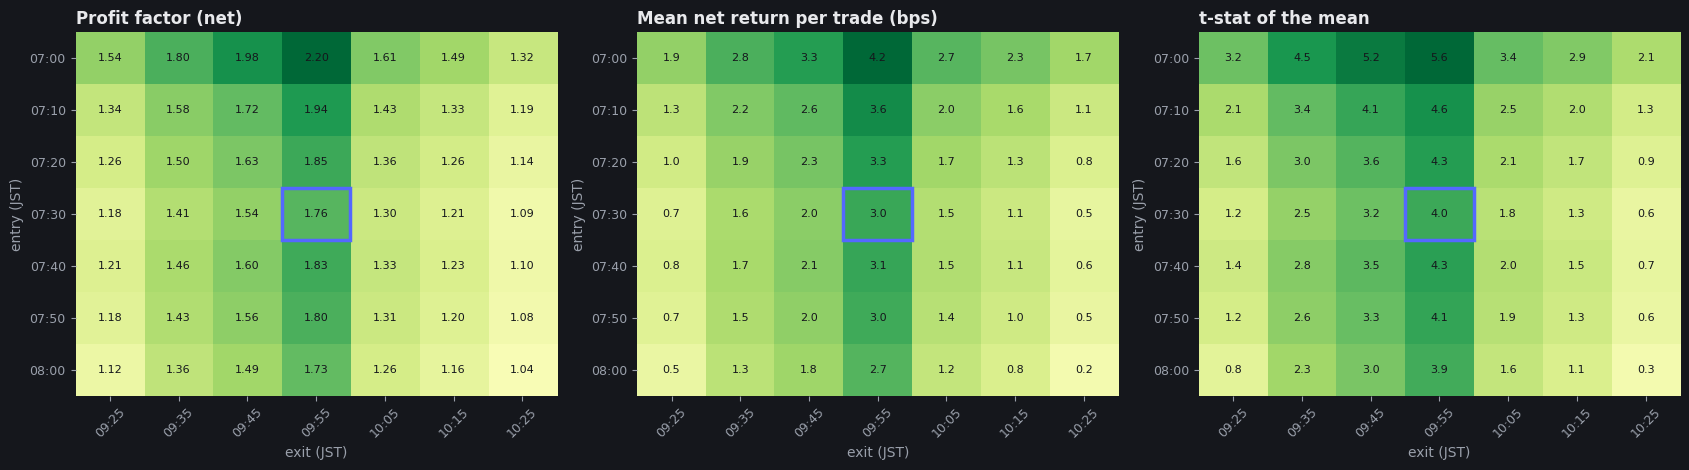

3x3 neighbourhood of the frozen window (07:30 -> 09:55):


,09:45,09:55,10:05
07:20,1.626,1.848,1.363
07:30,1.545,1.764,1.303
07:40,1.604,1.833,1.331


Center PF 1.764 | worst neighbour drop 26.1% (max 30%) | plateau NO | anti-cliff PASS
Cells with mean net > 0: 49 of 49 | cells with PF >= 1.2: 80% | frozen cell ranks #6 of 49 by mean net
   [FAIL] plateau (3x3, PF >= pf_min, N >= n_min)  ->  center PF 1.76
   [PASS] anti-cliff (3x3)  ->  worst drop 26.1% vs 30%
   [PASS] frozen cell not on grid edge
   [PASS] majority of grid cells have mean net > 0  ->  100% of cells


'PASS'

In [15]:
E0, X0 = to_min(ET), to_min(XT)
ENT = [E0 + d for d in range(-GRID_SPAN_MIN, GRID_SPAN_MIN + 1, GRID_STEP_MIN)]
EXI = [X0 + d for d in range(-GRID_SPAN_MIN, GRID_SPAN_MIN + 1, GRID_STEP_MIN)]
CENTER = (hhmm(E0), hhmm(X0))

TR = {(e, x): eng.run_gotobi_backtest(df_is, entry_time=hhmm(e), exit_time=hhmm(x)) for e in ENT for x in EXI}
SG = {k: summ(t) for k, t in TR.items()}
grid = lambda col: pd.DataFrame({hhmm(x): {hhmm(e): SG[(e, x)][col] for e in ENT} for x in EXI})
pf_g, n_g, mean_g, t_g = grid("pf").clip(upper=99), grid("n"), grid("mean"), grid("t")

def heatmap(ax, g, title, center=0.0, fmt="{:.1f}", mark=None):
    """Annotated heatmap, colour symmetric around `center`; blue square marks the frozen cell."""
    v = g.to_numpy(float)
    span = np.nanmax(np.abs(v - center)) or 1.0
    ax.imshow(v, cmap="RdYlGn", vmin=center - span, vmax=center + span, aspect="auto")
    ax.set_xticks(range(g.shape[1])); ax.set_xticklabels(g.columns, rotation=45, color=U.SUB)
    ax.set_yticks(range(g.shape[0])); ax.set_yticklabels(g.index, color=U.SUB)
    for (r, c), val_ in np.ndenumerate(v):
        ax.text(c, r, fmt.format(val_), ha="center", va="center", fontsize=8, color="#15171c")
    if mark:
        r, c = g.index.get_loc(mark[0]), g.columns.get_loc(mark[1])
        ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, ec=U.BLUE, lw=2.5))
    ax.set_xlabel("exit (JST)", color=U.SUB); ax.set_ylabel("entry (JST)", color=U.SUB)
    U.set_title(ax, title)

def plateau(pf, n, center, pf_min, n_min, max_drop):
    """Plateau + anti-cliff verdict of the 3x3 neighbourhood of `center`."""
    i, j = pf.index.get_loc(center[0]), pf.columns.get_loc(center[1])
    sl = (slice(max(i - 1, 0), i + 2), slice(max(j - 1, 0), j + 2))
    nb, nn, c = pf.iloc[sl], n.iloc[sl], float(pf.iloc[i, j])
    drop = float(max(0.0, (c - nb.min().min()) / c * 100)) if c > 0 else np.nan
    return dict(center_pf=c, worst_drop_pct=drop, plateau=bool((nb >= pf_min).all().all() and (nn >= n_min).all().all()),
                anticliff=bool(drop <= max_drop), edge=bool(i in (0, len(pf) - 1) or j in (0, len(pf.columns) - 1)), nb=nb, nn=nn)

pl = plateau(pf_g, n_g, CENTER, PF_MIN, N_MIN, MAX_DROP)
cells = mean_g.stack()
rank = int((cells > mean_g.loc[CENTER]).sum()) + 1

fig, axes = U.subplots(1, 3, figsize=(17, 4.8), grid=False)
heatmap(axes[0], pf_g, "Profit factor (net)", center=1.0, fmt="{:.2f}", mark=CENTER)
heatmap(axes[1], mean_g, "Mean net return per trade (bps)", center=0.0, mark=CENTER)
heatmap(axes[2], t_g, "t-stat of the mean", center=0.0, fmt="{:.1f}", mark=CENTER)
plt.tight_layout(); plt.show()

print(f"3x3 neighbourhood of the frozen window ({CENTER[0]} -> {CENTER[1]}):")
display(pl["nb"].round(3))
print(f"Center PF {pl['center_pf']:.3f} | worst neighbour drop {pl['worst_drop_pct']:.1f}% (max {MAX_DROP:g}%) | plateau {'YES' if pl['plateau'] else 'NO'} | anti-cliff {'PASS' if pl['anticliff'] else 'FAIL'}")
print(f"Cells with mean net > 0: {int((cells > 0).sum())} of {len(cells)} | cells with PF >= {PF_MIN}: {100 * (pf_g >= PF_MIN).to_numpy().mean():.0f}% | frozen cell ranks #{rank} of {len(cells)} by mean net")

C("3 Time window", "plateau (3x3, PF >= pf_min, N >= n_min)", pl["plateau"], f"center PF {pl['center_pf']:.2f}")
C("3 Time window", "anti-cliff (3x3)", pl["anticliff"], f"worst drop {pl['worst_drop_pct']:.1f}% vs {MAX_DROP:g}%")
C("3 Time window", "frozen cell not on grid edge", not pl["edge"])
C("3 Time window", "majority of grid cells have mean net > 0", (cells > 0).mean() > 0.5, f"{100 * (cells > 0).mean():.0f}% of cells")

### 3.1 WHERE DOES THE DRIFT LIVE? (INTRADAY PROFILE VS CONTROL DAYS)

Gross mean return from the entry bar (no costs), Gotobi days vs non-Gotobi business days (control, excluding the neighbouring business day of each Gotobi date), +-2 SE bands. Right: mean return per M5 step. A real Gotobi edge shows a positive slope **inside** the frozen window (shaded) and none on control days.

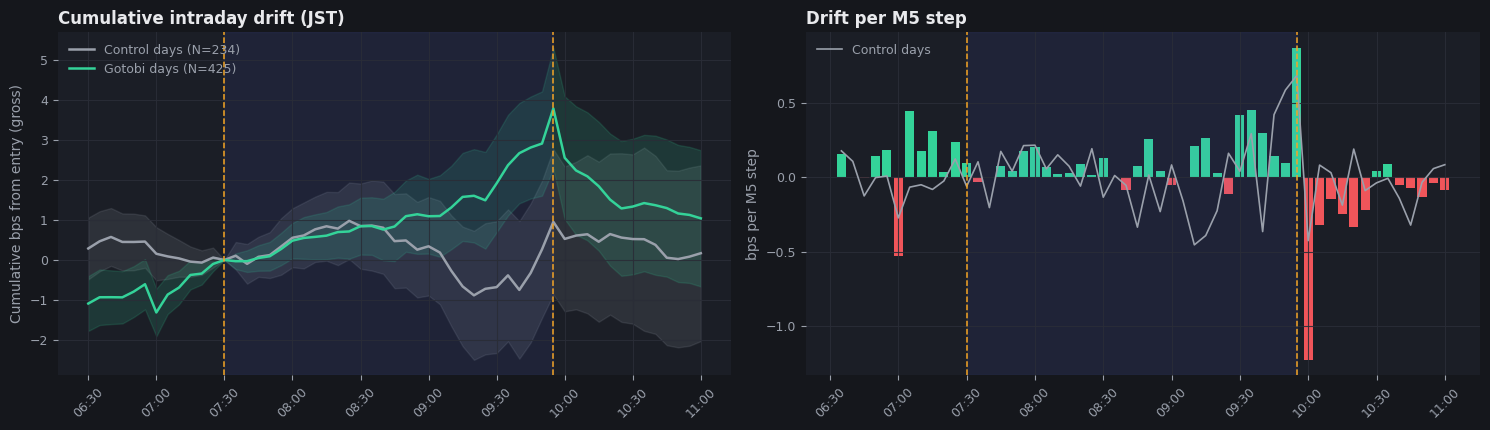

Gross drift entry -> exit: Gotobi +3.79 bps (SE 0.76) vs control +0.95 bps (SE 0.91)


In [16]:
gd = eng.gotobi_calendar(a, b).index
cd = eng.control_dates(a, b, exclude_neighbors=1)
prof_g = eng.intraday_profile(df_is, gd, "06:30", "11:00", ET)
prof_c = eng.intraday_profile(df_is, cd, "06:30", "11:00", ET)
lab, x = list(prof_g.index), np.arange(len(prof_g))

fig, (ax1, ax2) = U.subplots(1, 2, figsize=(15, 4.4))
for p, col, name in ((prof_c, U.SUB, f"Control days (N={int(prof_c['n'].max())})"), (prof_g, U.GREEN, f"Gotobi days (N={int(prof_g['n'].max())})")):
    ax1.plot(x, p["mean_cum_bps"], color=col, lw=1.8, label=name)
    ax1.fill_between(x, p["mean_cum_bps"] - 2 * p["se_cum_bps"], p["mean_cum_bps"] + 2 * p["se_cum_bps"], color=col, alpha=0.15)
ax2.bar(x, prof_g["mean_step_bps"], width=0.8, color=[U.GREEN if v > 0 else U.RED for v in prof_g["mean_step_bps"]])
ax2.plot(x, prof_c["mean_step_bps"], color=U.SUB, lw=1.2, label="Control days")
for ax in (ax1, ax2):
    ax.axvspan(lab.index(ET), lab.index(XT), color=U.BLUE, alpha=0.08)
    for t_ in (ET, XT):
        ax.axvline(lab.index(t_), color=U.ORANGE, ls="--", lw=1.1)
    ax.set_xticks(x[::6]); ax.set_xticklabels(lab[::6], rotation=45, color=U.SUB)
    U.legend(ax)
ax1.set_ylabel("Cumulative bps from entry (gross)", color=U.SUB); ax2.set_ylabel("bps per M5 step", color=U.SUB)
U.set_title(ax1, "Cumulative intraday drift (JST)"); U.set_title(ax2, "Drift per M5 step")
plt.tight_layout(); plt.show()
print(f"Gross drift entry -> exit: Gotobi {prof_g.loc[XT, 'mean_cum_bps']:+.2f} bps (SE {prof_g.loc[XT, 'se_cum_bps']:.2f}) vs control {prof_c.loc[XT, 'mean_cum_bps']:+.2f} bps (SE {prof_c.loc[XT, 'se_cum_bps']:.2f})")

## 4. COST SENSITIVITY AND BREAKEVEN

The spread is the whole cost of the strategy (one round-trip spread, charged at entry). Both sweeps run **without the spread filter** so the cost is isolated (with the filter, a larger `spread_scale` would also drop trades).
- **Flat spread** (`cost_mode="flat_pips"`): the robustness check the engine recommends for 2010-2020, when the feed spread is a modelled constant.
- **Feed scale** (`cost_mode="feed"`): the feed spread times `spread_scale` (placeholder 0.7 calibrated on 2024-26).

**Breakeven** = spread (or scale) where the mean net return crosses zero; **breakeven multiple** = breakeven / configured cost.

FLAT SPREAD SWEEP (in-sample, no spread filter)


,n,pf,mean,t,win,se
flat spread (pips),,,,,,
0.0,425.0,2.039,3.786,5.000,62.353,0.757
0.5,425.0,1.876,3.342,4.414,61.412,0.757
0.7,425.0,1.815,3.164,4.179,60.941,0.757
1.0,425.0,1.727,2.898,3.827,60.000,0.757
1.5,425.0,1.589,2.454,3.241,58.588,0.757
2.0,425.0,1.461,2.010,2.654,56.235,0.757
3.0,425.0,1.235,1.122,1.482,50.353,0.757
4.0,425.0,1.045,0.234,0.309,47.294,0.757
6.0,425.0,0.753,-1.541,-2.035,40.471,0.757


FEED SCALE SWEEP (in-sample, no spread filter)


,n,pf,mean,t,win,se
spread_scale,,,,,,
0.0,425.0,2.039,3.786,5.000,62.353,0.757
0.5,425.0,1.839,3.238,4.279,60.706,0.757
0.7,425.0,1.764,3.019,3.989,60.000,0.757
1.0,425.0,1.657,2.691,3.554,58.588,0.757
1.5,425.0,1.493,2.144,2.827,56.471,0.758
2.0,425.0,1.346,1.597,2.100,54.353,0.760
3.0,425.0,1.097,0.503,0.657,49.647,0.766
4.0,425.0,0.899,-0.590,-0.763,47.294,0.774
6.0,425.0,0.619,-2.776,-3.476,40.235,0.799


Breakeven flat spread: 4.26 pips | breakeven spread_scale: 3.46 (configured 0.7) | breakeven multiple (feed): 4.94x (min 2.0)


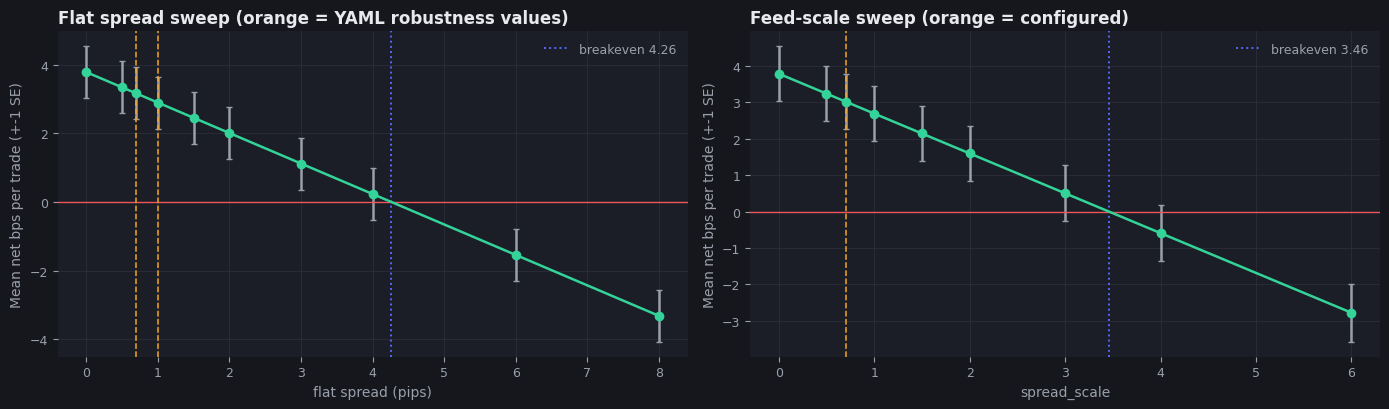

   [PASS] breakeven multiple >= breakeven_mult_min  ->  4.94x vs 2.0
   [PASS] mean net > 0 at every YAML flat spread  ->  worst +2.90 bps at 1 pips


'PASS'

In [17]:
NOFILT = dict(max_entry_spread_pips=float("inf"))
SPREADS = sorted({0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0, 8.0} | set(FLAT))
SCALES = sorted({0.0, 0.5, 1.0, 1.5, 2.0, 3.0, 4.0, 6.0} | {SCALE})
flat_tr = {}
for s in SPREADS:
    with U.engine_overrides(eng, flat_spread_pips=s):
        flat_tr[s] = eng.run_gotobi_backtest(df_is, cost_mode="flat_pips", **NOFILT)
feed_tr = {k: eng.run_gotobi_backtest(df_is, cost_mode="feed", spread_scale=k, **NOFILT) for k in SCALES}
flat_tbl, feed_tbl = parts_table(flat_tr), parts_table(feed_tr)
flat_tbl.index.name, feed_tbl.index.name = "flat spread (pips)", "spread_scale"

def breakeven(tbl):
    """Zero crossing of the mean net return (inf if it never crosses inside the grid and stays positive)."""
    z = U.interp_zero(tbl.index, tbl["mean"])
    return np.inf if np.isnan(z) and (tbl["mean"] > 0).all() else z

be_flat, be_scale = breakeven(flat_tbl), breakeven(feed_tbl)
if MODE == "feed":
    be_mult = be_scale / SCALE
elif MODE == "flat_pips":
    be_mult = be_flat / float(eng.ENGINE_DEFAULTS["flat_spread_pips"])
else:
    be_mult = np.nan

print("FLAT SPREAD SWEEP (in-sample, no spread filter)"); display(flat_tbl.round(3))
print("FEED SCALE SWEEP (in-sample, no spread filter)"); display(feed_tbl.round(3))
print(f"Breakeven flat spread: {be_flat:.2f} pips | breakeven spread_scale: {be_scale:.2f} (configured {SCALE:g}) | breakeven multiple ({MODE}): {be_mult:.2f}x (min {ACC['breakeven_mult_min']})")

fig, (ax1, ax2) = U.subplots(1, 2, figsize=(14, 4.2))
for ax, tbl, marks, be, xl in ((ax1, flat_tbl, FLAT, be_flat, "flat spread (pips)"), (ax2, feed_tbl, [SCALE], be_scale, "spread_scale")):
    ax.errorbar(tbl.index, tbl["mean"], yerr=tbl["se"], color=U.GREEN, marker="o", lw=1.8, ecolor=U.SUB, capsize=2)
    ax.axhline(0, color=U.RED, lw=1.0)
    for m in marks:
        ax.axvline(m, color=U.ORANGE, ls="--", lw=1.1)
    if np.isfinite(be):
        ax.axvline(be, color=U.BLUE, ls=":", lw=1.4, label=f"breakeven {be:.2f}")
        U.legend(ax, "upper right")
    ax.set_xlabel(xl, color=U.SUB); ax.set_ylabel("Mean net bps per trade (+-1 SE)", color=U.SUB)
U.set_title(ax1, "Flat spread sweep (orange = YAML robustness values)"); U.set_title(ax2, "Feed-scale sweep (orange = configured)")
plt.tight_layout(); plt.show()

C("4 Costs", "breakeven multiple >= breakeven_mult_min", None if np.isnan(be_mult) else be_mult >= float(ACC["breakeven_mult_min"]), f"{be_mult:.2f}x vs {ACC['breakeven_mult_min']}")
C("4 Costs", "mean net > 0 at every YAML flat spread", bool((flat_tbl.loc[FLAT, "mean"] > 0).all()), f"worst {flat_tbl.loc[FLAT, 'mean'].min():+.2f} bps at {max(FLAT):g} pips")

## 5. CALENDAR ANATOMY

Descriptive, not for re-tuning: **which part of the calendar carries the edge?** Mean net bps (+-1 SE) by Gotobi label, weekday, US-DST season of the entry (winter = rollover 30 min before entry) and by whether the date was shifted to the previous business day. Then **leave-one-label-out** (the edge must not be one day of the month) and alternative calendar conventions (shift rule, month-end).

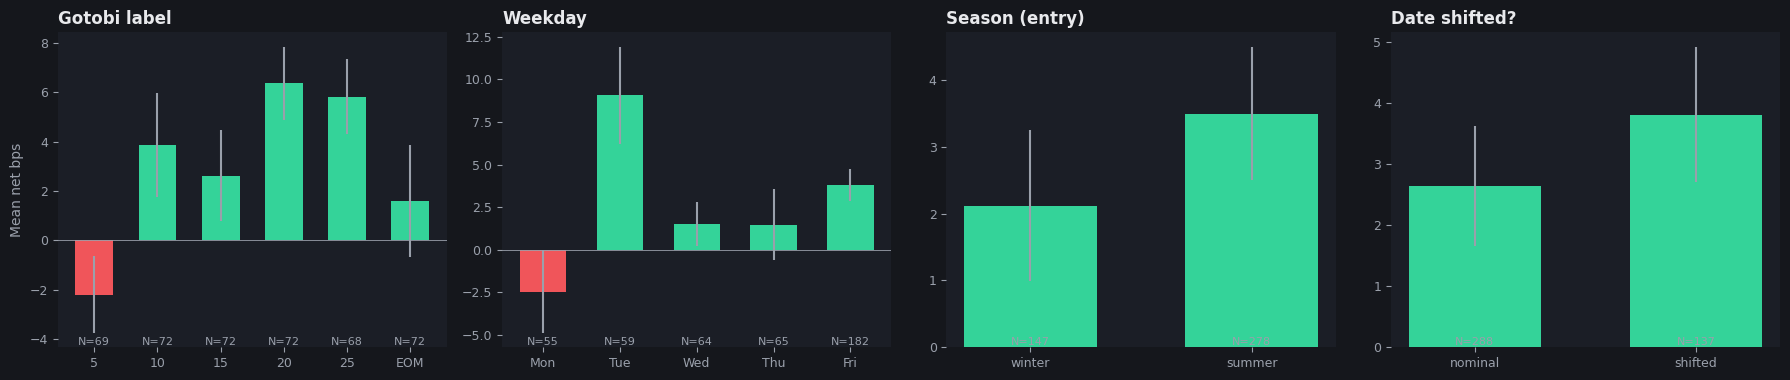

Gotobi label


,n,pf,mean,t,win,se
5,69.0,0.612,-2.199,-1.413,42.029,1.557
10,72.0,2.052,3.861,1.832,56.944,2.108
15,72.0,1.603,2.621,1.427,63.889,1.837
20,72.0,5.214,6.360,4.288,75.000,1.483
25,68.0,3.322,5.818,3.828,73.529,1.520
EOM,72.0,1.266,1.593,0.697,48.611,2.286


Weekday


,n,pf,mean,t,win,se
Mon,55.0,0.695,-2.451,-1.009,38.182,2.429
Tue,59.0,4.486,9.072,3.191,72.881,2.843
Wed,64.0,1.487,1.511,1.156,62.500,1.307
Thu,65.0,1.297,1.471,0.712,56.923,2.068
Fri,182.0,2.227,3.794,4.031,62.637,0.941


Season (entry)


,n,pf,mean,t,win,se
winter,147.0,1.544,2.116,1.874,58.503,1.129
summer,278.0,1.877,3.497,3.527,60.791,0.991


... (4 outputs left out)

CALENDAR CONVENTIONS (in-sample)


,n,pf,mean,t,win,se
configured,425.0,1.764,3.019,3.989,60.000,0.757
shift_rule=next,425.0,1.605,2.682,3.342,57.882,0.802
shift_rule=none (skip),288.0,1.593,2.645,2.682,59.028,0.986
no month-end,356.0,1.938,3.298,4.240,62.079,0.778
month-end only,72.0,1.266,1.593,0.697,48.611,2.286


   [PASS] leave-one-label-out: PF >= pf_min in every case  ->  min PF 1.53 (without 20)
   [FAIL] mean net > 0 in every Gotobi label  ->  5/6 labels positive


'FAIL'

In [18]:
ORDER = [str(d) for d in RULE["gotobi_days"]] + (["EOM"] if RULE["include_month_end"] else [])
winter = ~eng.us_dst_mask(pd.DatetimeIndex(base["entry_time"]))
DOW = ["Mon", "Tue", "Wed", "Thu", "Fri"]
anat = {
    "Gotobi label": parts_table({k: base[base["label"] == k] for k in ORDER}),
    "Weekday": parts_table({DOW[d]: base[base["dow"] == d] for d in sorted(base["dow"].unique())}),
    "Season (entry)": parts_table({"winter": base[winter], "summer": base[~winter]}),
    "Date shifted?": parts_table({"nominal": base[~base["shifted"]], "shifted": base[base["shifted"]]}),
}
fig, axes = U.subplots(1, 4, figsize=(18, 3.9), grid=False)
for ax, (name, tbl) in zip(axes, anat.items()):
    bars(ax, tbl, name)
axes[0].set_ylabel("Mean net bps", color=U.SUB)
plt.tight_layout(); plt.show()
for name, tbl in anat.items():
    print(name); display(tbl.round(3))

# ---- leave-one-label-out ----
loo = parts_table({"all labels": base, **{f"without {k}": base[base["label"] != k] for k in ORDER}})
print("LEAVE-ONE-LABEL-OUT"); display(loo.round(3))

# ---- alternative calendar conventions (descriptive) ----
VARS = {"configured": {}, "shift_rule=next": dict(shift_rule="next"), "shift_rule=none (skip)": dict(shift_rule="none"),
        "no month-end": dict(include_month_end=False), "month-end only": dict(gotobi_days=())}
var_tbl = parts_table({k: eng.run_gotobi_backtest(df_is, **kw) for k, kw in VARS.items()})
print("CALENDAR CONVENTIONS (in-sample)"); display(var_tbl.round(3))

C("5 Calendar", "leave-one-label-out: PF >= pf_min in every case", bool((loo["pf"] >= PF_MIN).all()), f"min PF {loo['pf'].min():.2f} ({loo['pf'].idxmin()})")
C("5 Calendar", "mean net > 0 in every Gotobi label", bool((anat["Gotobi label"]["mean"] > 0).all()), f"{int((anat['Gotobi label']['mean'] > 0).sum())}/{len(ORDER)} labels positive")

## 6. EXECUTION FILTER AND ENTRY SPREAD

The feed spread at the entry bar is the engine's cost **and** a filter (`max_entry_spread_pips`). Three views: (left) the Axi-equivalent spread distribution by season, (centre) gross vs net edge by spread quantile, (right) what each cap costs in signals and what it earns **per signal** (mean net x share of signals kept), so a filter that only shrinks N is not mistaken for improvement.

Gate: the configured cap must not discard more than `max_signal_loss` of the signals.

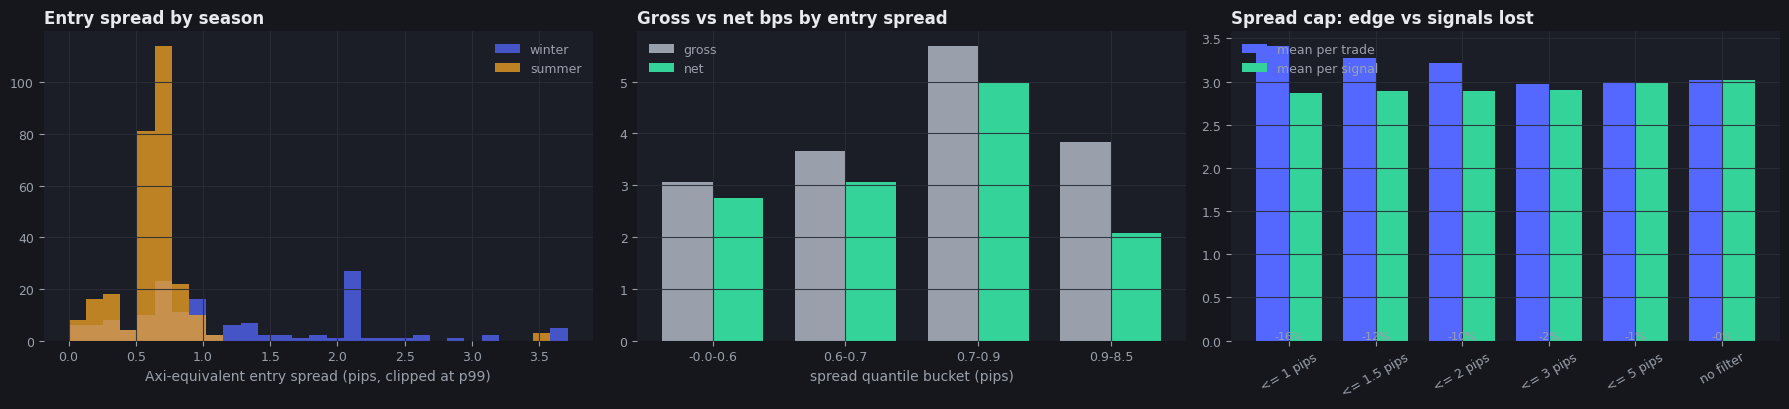

ENTRY-SPREAD BUCKETS


,n,gross,net,cost,winter_%
-0.0-0.6,97,3.06,2.76,0.30,28.87
0.6-0.7,201,3.67,3.06,0.61,14.43
0.7-0.9,47,5.69,4.97,0.71,40.43
0.9-8.5,80,3.84,2.07,1.77,88.75


SPREAD CAP


,n,pf,mean,t,win,se,loss_%,bps_per_signal
<= 1 pips,357.0,1.877,3.411,4.064,60.504,0.839,16.000,2.865
<= 1.5 pips,376.0,1.842,3.271,4.008,61.170,0.816,11.529,2.894
<= 2 pips,382.0,1.830,3.212,3.990,60.995,0.805,10.118,2.887
<= 3 pips,415.0,1.768,2.970,3.932,60.241,0.755,2.353,2.900
<= 5 pips,422.0,1.769,2.999,3.982,59.953,0.753,0.706,2.978
no filter,425.0,1.764,3.019,3.989,60.000,0.757,0.000,3.019


Configured cap: no filter -> signal loss 0.0% (max 5%)
   [PASS] signal loss of configured spread cap <= max_signal_loss  ->  0.0%


'PASS'

In [19]:
cap0 = eng.ENGINE_DEFAULTS["max_entry_spread_pips"]
cap0 = np.inf if cap0 is None else float(cap0)
CAPS = sorted({1.0, 1.5, 2.0, 3.0, 5.0, np.inf} | {cap0})
cap_tr = {c: eng.run_gotobi_backtest(df_is, max_entry_spread_pips=c) for c in CAPS}
t_all = cap_tr[np.inf]
n_all = len(t_all)
cap_lbl = lambda c: "no filter" if np.isinf(c) else f"<= {c:g} pips"
cap_tbl = parts_table({cap_lbl(c): t for c, t in cap_tr.items()})
cap_tbl["loss_%"] = [100 * (1 - len(t) / n_all) for t in cap_tr.values()]
cap_tbl["bps_per_signal"] = [t["pnl_bps"].sum() / n_all for t in cap_tr.values()]
signal_loss = 1 - len(cap_tr[cap0]) / n_all

bk = pd.qcut(t_all["spread_pips"], ROLL_BINS, duplicates="drop")
bk_lbl = [f"{iv.left:.1f}-{iv.right:.1f}" for iv in bk.cat.categories]
bkt = t_all.groupby(bk, observed=True).agg(n=("pnl_bps", "size"), gross=("pnl_gross_bps", "mean"), net=("pnl_bps", "mean"), cost=("cost_bps", "mean"))
bkt.index = bk_lbl
w_all = ~eng.us_dst_mask(pd.DatetimeIndex(t_all["entry_time"]))
bkt["winter_%"] = 100 * t_all.groupby(bk, observed=True).apply(lambda g: (~eng.us_dst_mask(pd.DatetimeIndex(g["entry_time"]))).mean()).to_numpy()

fig, axes = U.subplots(1, 3, figsize=(18, 4.2))
top = float(t_all["spread_pips"].quantile(0.99))
bins = np.linspace(0, max(top, 1.0), 30)
axes[0].hist(t_all.loc[w_all, "spread_pips"].clip(upper=top), bins=bins, color=U.BLUE, alpha=0.75, label="winter")
axes[0].hist(t_all.loc[~w_all, "spread_pips"].clip(upper=top), bins=bins, color=U.ORANGE, alpha=0.75, label="summer")
axes[0].set_xlabel("Axi-equivalent entry spread (pips, clipped at p99)", color=U.SUB); U.legend(axes[0], "upper right"); U.set_title(axes[0], "Entry spread by season")
xb, w = np.arange(len(bkt)), 0.38
axes[1].bar(xb - w / 2, bkt["gross"], w, color=U.SUB, label="gross"); axes[1].bar(xb + w / 2, bkt["net"], w, color=[U.GREEN if v > 0 else U.RED for v in bkt["net"]], label="net")
axes[1].axhline(0, color=U.SUB, lw=0.6); axes[1].set_xticks(xb); axes[1].set_xticklabels(bkt.index, color=U.SUB)
axes[1].set_xlabel("spread quantile bucket (pips)", color=U.SUB); U.legend(axes[1]); U.set_title(axes[1], "Gross vs net bps by entry spread")
xc = np.arange(len(cap_tbl))
axes[2].bar(xc - w / 2, cap_tbl["mean"], w, color=U.BLUE, label="mean per trade"); axes[2].bar(xc + w / 2, cap_tbl["bps_per_signal"], w, color=U.GREEN, label="mean per signal")
axes[2].axhline(0, color=U.SUB, lw=0.6); axes[2].set_xticks(xc); axes[2].set_xticklabels(cap_tbl.index, rotation=30, color=U.SUB)
for i, l in enumerate(cap_tbl["loss_%"]):
    axes[2].text(i, axes[2].get_ylim()[0], f"-{l:.0f}%", color=U.SUB, fontsize=8, ha="center", va="bottom")
U.legend(axes[2]); U.set_title(axes[2], "Spread cap: edge vs signals lost")
plt.tight_layout(); plt.show()

print("ENTRY-SPREAD BUCKETS"); display(bkt.round(2))
print("SPREAD CAP"); display(cap_tbl.round(3))
print(f"Configured cap: {cap_lbl(cap0)} -> signal loss {100 * signal_loss:.1f}% (max {100 * share(ACC['max_signal_loss']):.0f}%)")
C("6 Execution", "signal loss of configured spread cap <= max_signal_loss", signal_loss <= share(ACC["max_signal_loss"]), f"{100 * signal_loss:.1f}%")

## 7. STABILITY THROUGH TIME

Annual mean net bps (+-1 SE), the YAML `periods`, and a rolling mean over `acceptance.roll_trades` trades. A Gotobi edge that only lived in one regime (e.g. a single multi-year stretch) would show up here before it reaches the OOS test.

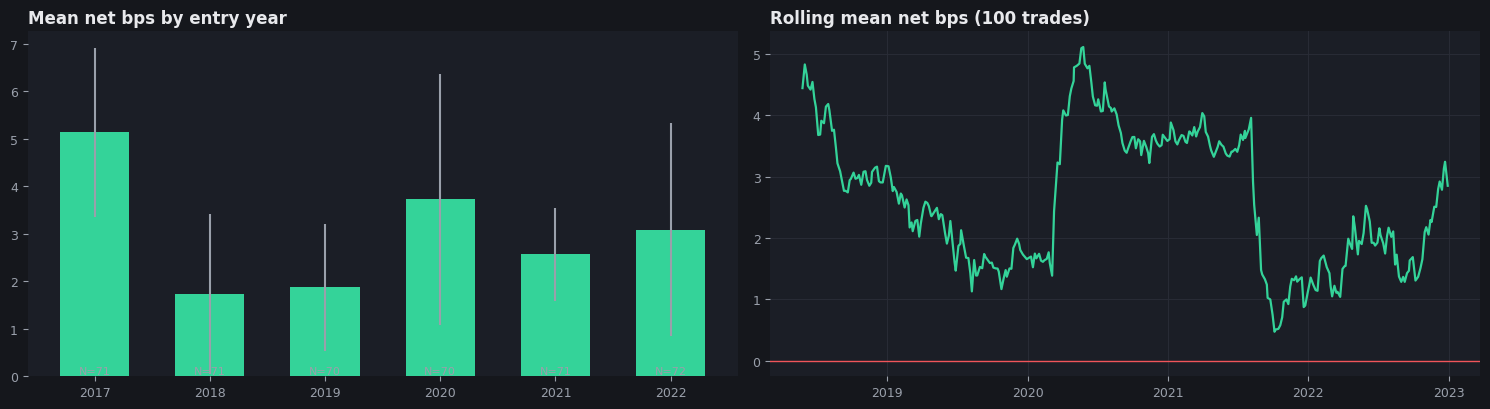

BY YEAR


,n,pf,mean,t,win,se
2017,71.0,2.560,5.136,2.891,71.831,1.776
2018,71.0,1.395,1.726,1.023,60.563,1.687
2019,70.0,1.559,1.869,1.400,61.429,1.335
2020,70.0,1.770,3.723,1.413,52.857,2.636
2021,71.0,2.311,2.566,2.612,59.155,0.982
2022,72.0,1.524,3.088,1.373,54.167,2.250


BY PERIOD (YAML periods, in-sample part)


,n,mean,mean_bps,median_bps,std_bps,t,p_one,pf,win_rate,sum_bps
2017-2022,425.0,3.019,3.019,2.175,15.604,3.989,0.0,1.764,0.6,1283.22


Positive years: 6/6 (need 4.5) | rolling window > 0 in 100% of the sample | worst rolling mean +0.47 bps
   [PASS] positive in-sample years >= years_pos_min  ->  6/6 vs 4.5
   [PASS] every YAML period with data has mean net > 0  ->  2017-2022: +3.0


'PASS'

In [20]:
yr = pd.to_datetime(base["entry_date"]).dt.year
by_year = parts_table({int(y): g for y, g in base.groupby(yr)})
per = eng.period_stats(base, cfg["periods"]).astype(float)
per = per[per["n"] > 0]
ROLL = int(ACC["roll_trades"])
roll = base.set_index(pd.to_datetime(base["entry_date"]))["pnl_bps"].rolling(ROLL).mean().dropna()
need = float(ACC["years_pos_min"])
need = need if need > 1 else need * len(by_year)
n_pos = int((by_year["mean"] > 0).sum())

fig, (ax1, ax2) = U.subplots(1, 2, figsize=(15, 4.2), grid=False)
bars(ax1, by_year, "Mean net bps by entry year")
ax2.set_facecolor(U.PANEL); ax2.grid(True, color=U.GRIDC, alpha=0.9)
ax2.plot(roll.index, roll, color=U.GREEN, lw=1.6); ax2.axhline(0, color=U.RED, lw=1.0)
ax2.fill_between(roll.index, 0, roll, where=roll < 0, color=U.RED, alpha=0.25)
U.set_title(ax2, f"Rolling mean net bps ({ROLL} trades)")
plt.tight_layout(); plt.show()

print("BY YEAR"); display(by_year.round(3))
print("BY PERIOD (YAML periods, in-sample part)"); display(per.round(3))
print(f"Positive years: {n_pos}/{len(by_year)} (need {need:.1f}) | rolling window > 0 in {100 * (roll > 0).mean():.0f}% of the sample | worst rolling mean {roll.min():+.2f} bps")
C("7 Stability", "positive in-sample years >= years_pos_min", n_pos >= need, f"{n_pos}/{len(by_year)} vs {need:.1f}")
C("7 Stability", "every YAML period with data has mean net > 0", bool((per["mean"] > 0).all()), ", ".join(f"{k}: {v:+.1f}" for k, v in per["mean"].items()))

## 8. PASS / FAIL SUMMARY

In [21]:
chk = C.frame()
display(chk.style.map(lambda s: {"PASS": "color:#34d399", "FAIL": "color:#f0555a", "SKIP": "color:#f5a524"}.get(s, ""), subset=["status"]))
cnt = C.counts()
print(f"PASS {cnt['PASS']} | FAIL {cnt['FAIL']} | SKIP {cnt['SKIP']}")

,section,name,status,detail
0,2 Setup,engine validate (in-sample),PASS,
1,2 Setup,N in-sample >= n_min,FAIL,425 vs 600
2,2 Setup,PF net (in-sample) >= pf_min,PASS,1.764 vs 1.2
3,2 Setup,t net (in-sample) >= min_t_net,PASS,3.99 vs 2.5
4,3 Time window,"plateau (3x3, PF >= pf_min, N >= n_min)",FAIL,center PF 1.76
5,3 Time window,anti-cliff (3x3),PASS,worst drop 26.1% vs 30%
6,3 Time window,frozen cell not on grid edge,PASS,
7,3 Time window,majority of grid cells have mean net > 0,PASS,100% of cells
8,4 Costs,breakeven multiple >= breakeven_mult_min,PASS,4.94x vs 2.0
9,4 Costs,mean net > 0 at every YAML flat spread,PASS,worst +2.90 bps at 1 pips


PASS 12 | FAIL 3 | SKIP 0


## 9. VERDICT AND HAND-OFF TO NOTEBOOK 03

In [22]:
ready = cnt["FAIL"] == 0
print("=" * 80)
print("9. SUMMARY OF IN-SAMPLE SENSITIVITY")
print("=" * 80)
print(f"""
1. Time window: plateau {'YES' if pl['plateau'] else 'NO'}, worst neighbour drop {pl['worst_drop_pct']:.1f}% (max {MAX_DROP:g}%); {int((cells > 0).sum())}/{len(cells)} cells with mean net > 0; frozen cell ranks #{rank}.
2. Costs: breakeven {be_flat:.2f} flat pips / scale {be_scale:.2f} -> {be_mult:.2f}x the configured cost (min {ACC['breakeven_mult_min']}).
3. Calendar: weakest leave-one-label-out PF {loo['pf'].min():.2f} ({loo['pf'].idxmin()}); {int((anat['Gotobi label']['mean'] > 0).sum())}/{len(ORDER)} labels positive.
4. Execution: spread cap {cap_lbl(cap0)} discards {100 * signal_loss:.1f}% of the signals.
5. Stability: {n_pos}/{len(by_year)} positive years; rolling mean > 0 in {100 * (roll > 0).mean():.0f}% of windows.

Checks: PASS {cnt['PASS']} | FAIL {cnt['FAIL']} | SKIP {cnt['SKIP']}
Next step: {'proceed to 03_Gotobi_Robustness_Testing with the frozen rules.' if ready else 'at least one gate failed. Do NOT re-tune the window or the calendar on this result: document it and carry it to notebook 03 as a known weakness.'}
""")

save_json(cfg, "02_sensitivity.json", dict(
    window=dict(is_start=a.date(), is_end=b.date(), years=years_is),
    baseline_is=B, mean_cost_bps=base["cost_bps"].mean(), mean_gross_bps=base["pnl_gross_bps"].mean(),
    time_grid=dict(center=CENTER, rank_by_mean=rank, share_cells_positive=float((cells > 0).mean()),
                   **{k: v for k, v in pl.items() if k not in ("nb", "nn")}),
    costs=dict(breakeven_flat_pips=be_flat, breakeven_scale=be_scale, breakeven_mult=be_mult),
    calendar=dict(loo_min_pf=float(loo["pf"].min()), by_label_mean_bps=anat["Gotobi label"]["mean"].to_dict()),
    execution=dict(cap=cap0, signal_loss=signal_loss),
    stability=dict(years_positive=n_pos, years=len(by_year), worst_rolling_bps=float(roll.min())),
    checks=C.items, counts=cnt, ready_for_03=ready))

9. SUMMARY OF IN-SAMPLE SENSITIVITY

1. Time window: plateau NO, worst neighbour drop 26.1% (max 30%); 49/49 cells with mean net > 0; frozen cell ranks #6.
2. Costs: breakeven 4.26 flat pips / scale 3.46 -> 4.94x the configured cost (min 2.0).
3. Calendar: weakest leave-one-label-out PF 1.53 (without 20); 5/6 labels positive.
4. Execution: spread cap no filter discards 0.0% of the signals.
5. Stability: 6/6 positive years; rolling mean > 0 in 100% of windows.

Checks: PASS 12 | FAIL 3 | SKIP 0
Next step: at least one gate failed. Do NOT re-tune the window or the calendar on this result: document it and carry it to notebook 03 as a known weakness.

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy/02_sensitivity.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/USDJPY_Gotobi/runs/v1_axi_usdjpy/02_sensitivity.json')